# Introduction to Seaborn

## Learning objectives

By the end of this notebook you will be able to:

- explain what Seaborn adds to Matplotlib
- load Seaborn's example datasets
- understand figure-level and axes-level functions
- set themes, contexts and colour palettes

## Introduction

Seaborn is a statistical plotting library built on Matplotlib. It works directly with pandas DataFrames:
you name the columns for x, y and colour, and Seaborn groups the data, computes summaries (means,
confidence intervals, density curves) and adds legends. Charts that take twenty lines in Matplotlib take
one in Seaborn, and because the result is Matplotlib, everything from module 7 still works for fine-tuning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
RAW = "../datasets/raw/"

In [2]:
sns.__version__

'0.13.2'

## Example datasets

Seaborn downloads small, well-known datasets (an internet connection is needed the first time). This
module uses:

| dataset | rows | about |
|---|---|---|
| `penguins` | 344 | body measurements of three penguin species on three islands |
| `tips` | 244 | restaurant bills and tips |
| `fmri` | 1064 | brain signal over time in an imaging experiment |
| `flights` | 144 | monthly airline passengers, 1949-1960 |
| `titanic` | 891 | passengers and survival |

In [3]:
penguins = sns.load_dataset("penguins")
print(penguins.shape)
penguins.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [4]:
penguins.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

## The data-to-plot pattern

Name the DataFrame and the columns. `hue` maps a column to colour and adds a legend automatically.

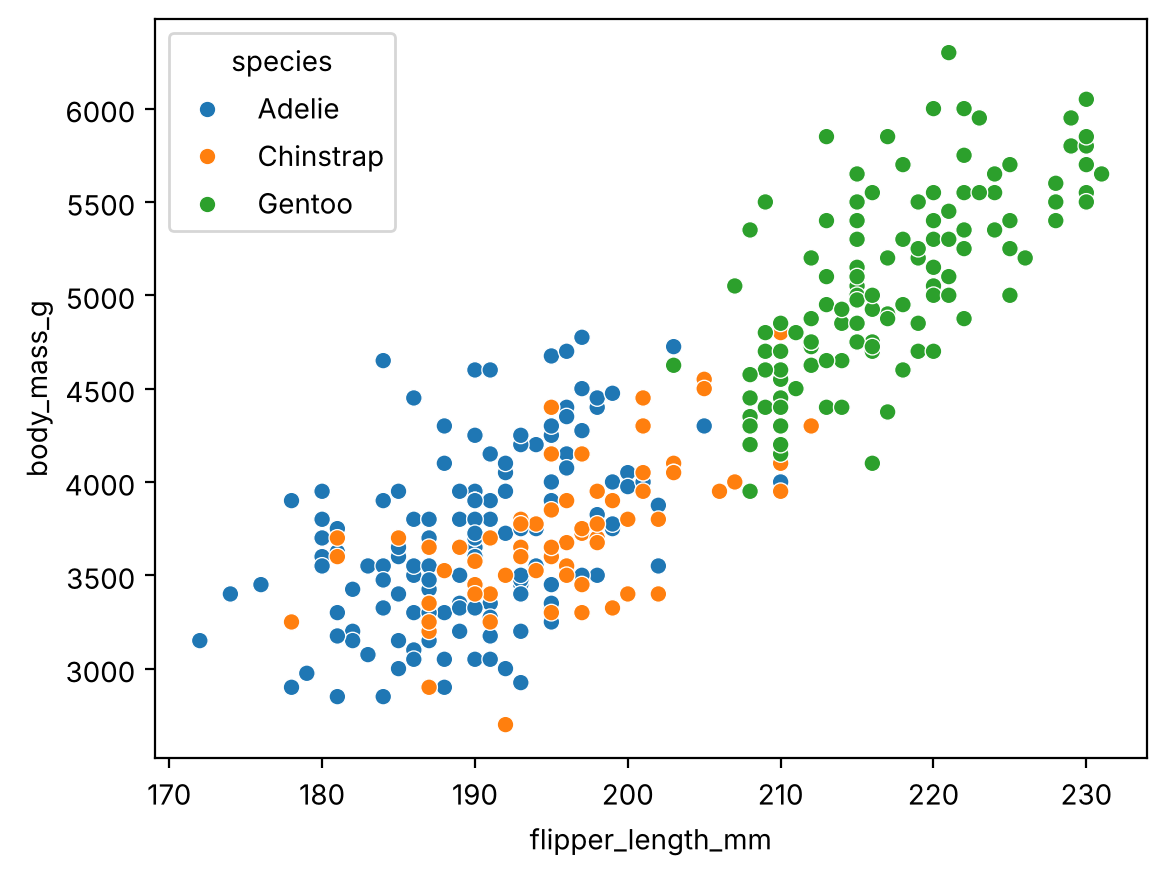

In [5]:
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species")
plt.show()

The same plot in plain Matplotlib needs a loop over species, a colour for each and a legend call.
Seaborn handles all that and drops rows with missing values.

## Two kinds of function

| | axes-level | figure-level |
|---|---|---|
| examples | `scatterplot`, `histplot`, `boxplot`, `heatmap` | `relplot`, `displot`, `catplot`, `lmplot`, `pairplot` |
| draws on | one Matplotlib Axes (`ax=`) | its own figure, possibly many panels |
| size | `figsize` of your figure | `height=` and `aspect=` |
| panels | you arrange them | `col=` and `row=` make small multiples |

Axes-level functions fit into your own `plt.subplots` layout:

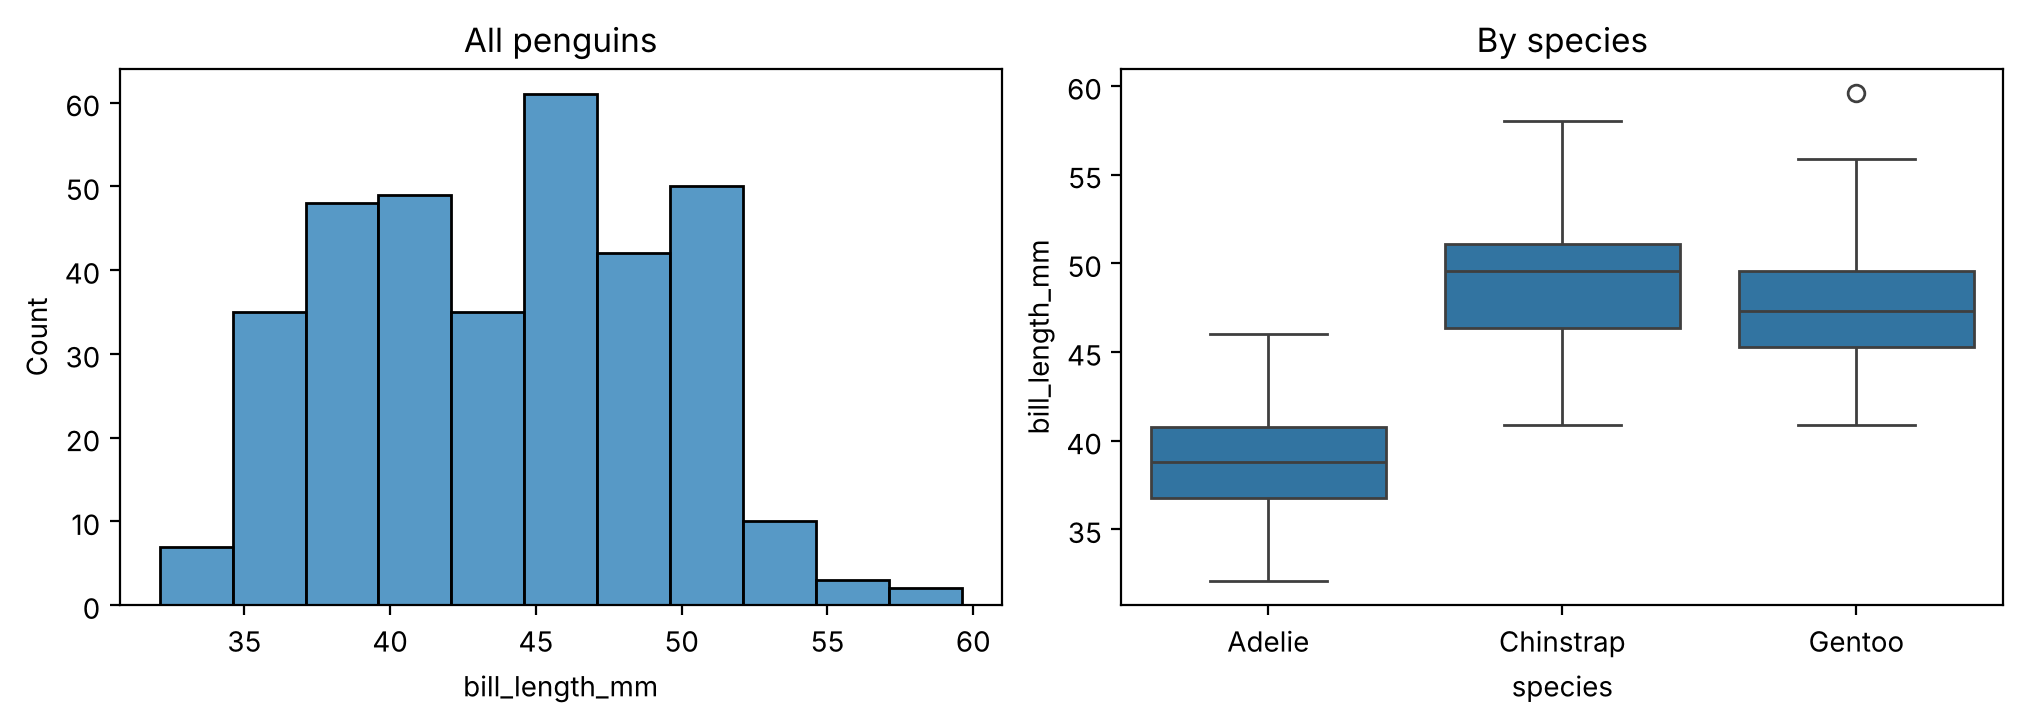

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
sns.histplot(data=penguins, x="bill_length_mm", ax=axes[0])
sns.boxplot(data=penguins, x="species", y="bill_length_mm", ax=axes[1])
axes[0].set_title("All penguins")
axes[1].set_title("By species")
plt.show()

Figure-level functions make panels for you:

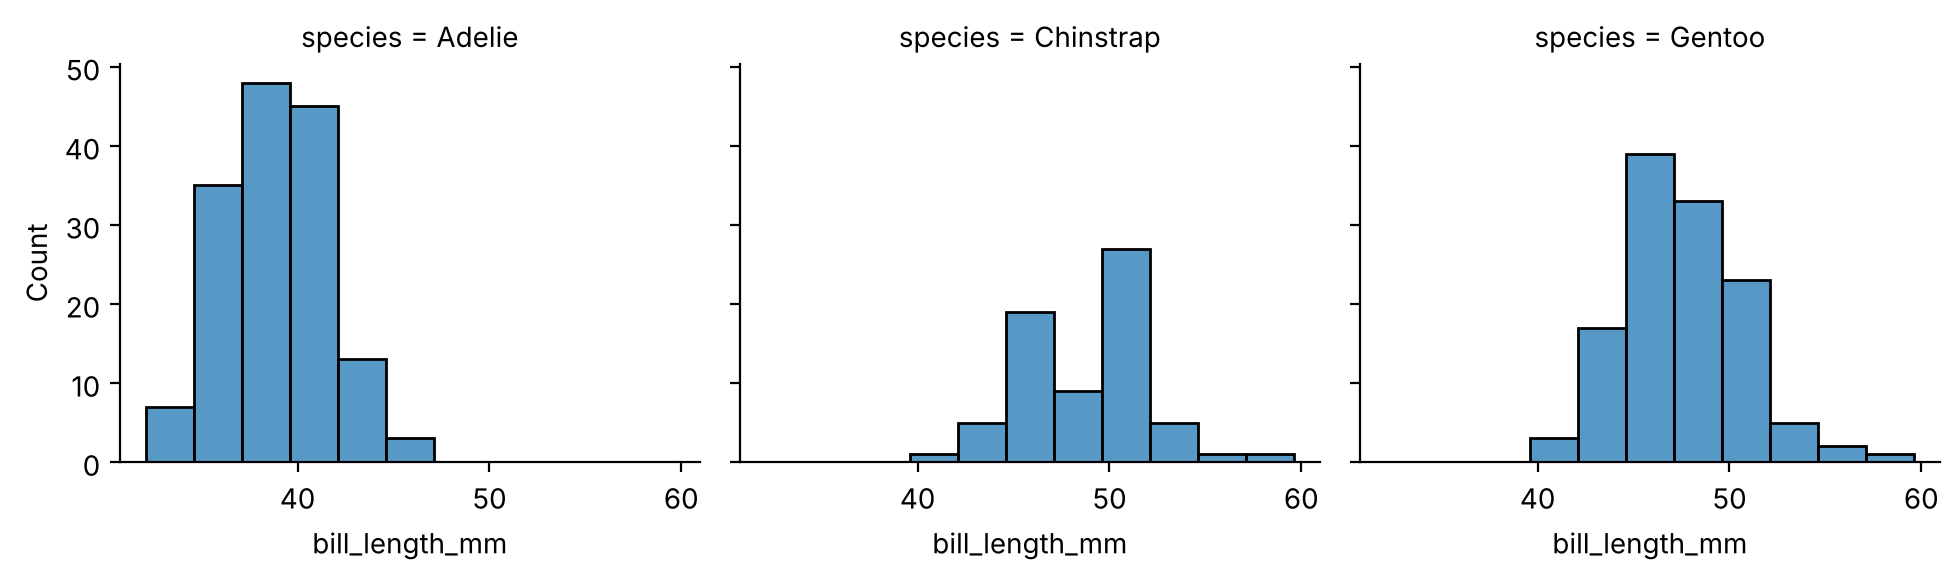

In [7]:
sns.displot(data=penguins, x="bill_length_mm", col="species", height=3, aspect=1.1)
plt.show()

## Themes

`sns.set_theme()` sets a style for every plot that follows. Styles: `darkgrid` (default), `whitegrid`,
`dark`, `white`, `ticks`.

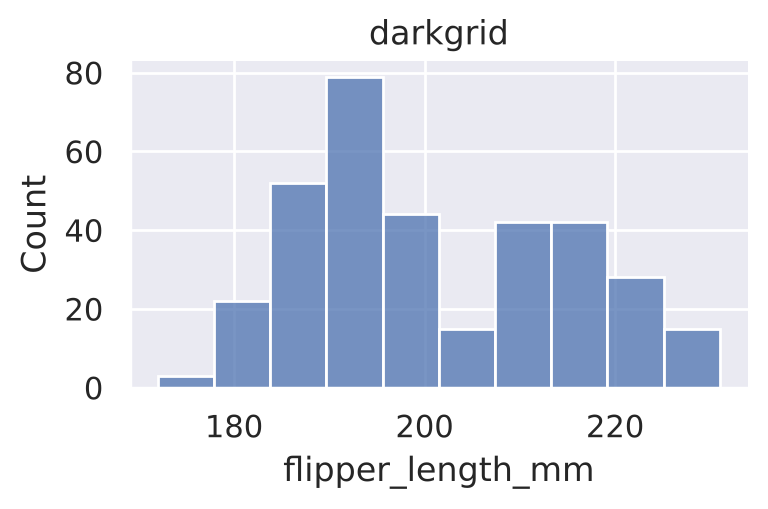

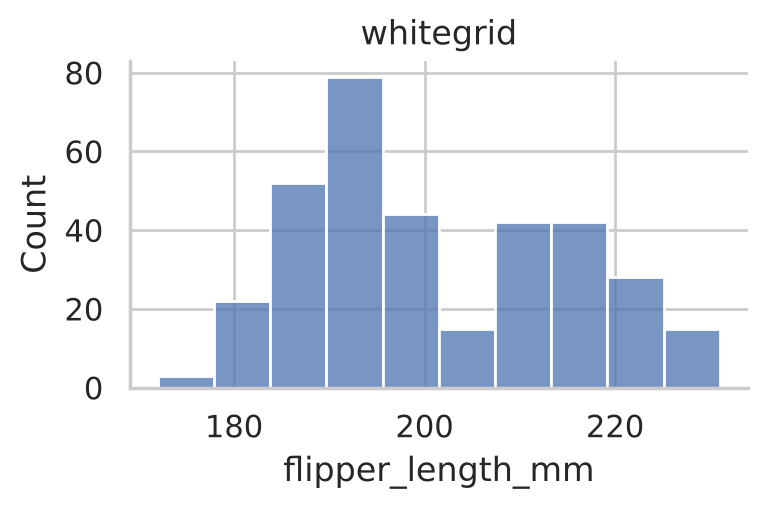

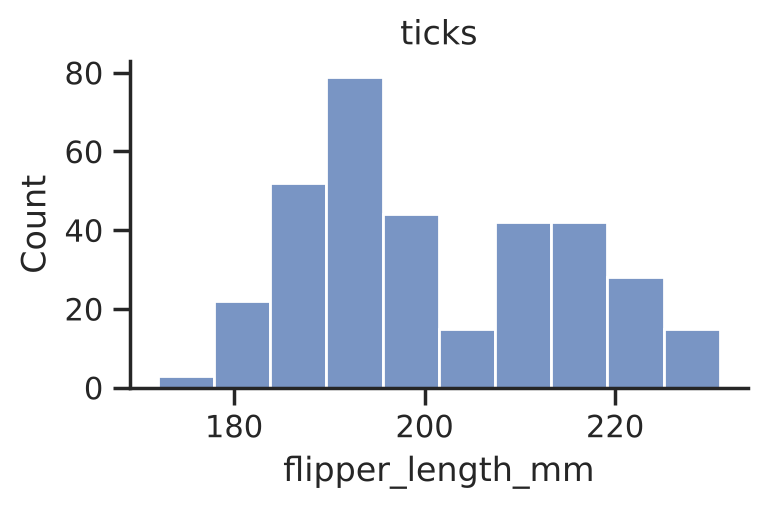

In [8]:
for style in ["darkgrid", "whitegrid", "ticks"]:
    sns.set_theme(style=style)
    g = sns.displot(data=penguins, x="flipper_length_mm", height=2.5, aspect=1.6)
    g.ax.set_title(style)
    plt.show()
sns.set_theme(style="whitegrid")

`sns.despine()` removes the top and right borders. **Contexts** scale fonts and lines for where the
figure will be seen: `paper`, `notebook` (default), `talk`, `poster`.

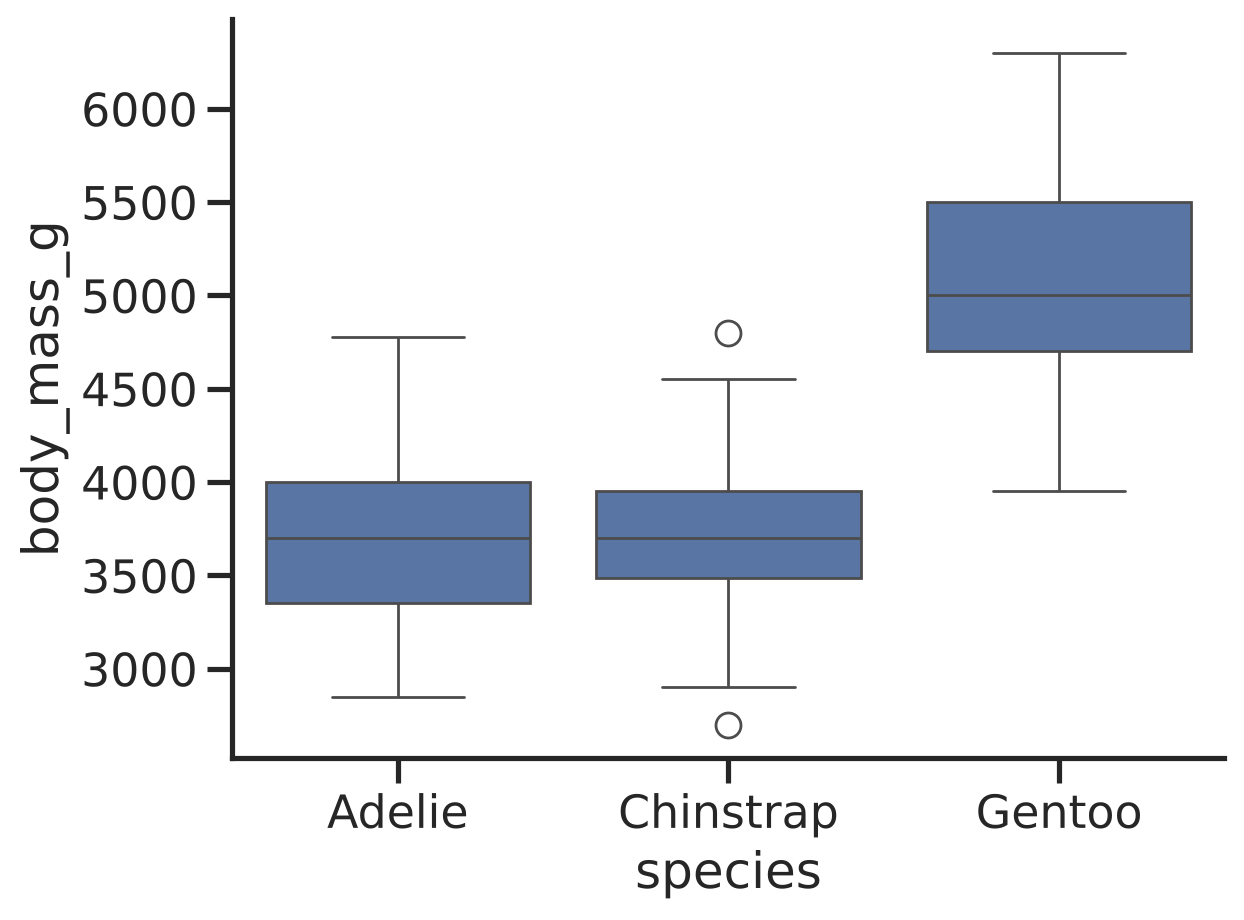

In [9]:
sns.set_theme(style="ticks", context="talk")
sns.boxplot(data=penguins, x="species", y="body_mass_g")
sns.despine()
plt.show()
sns.set_theme(style="whitegrid", context="notebook")

## Colour palettes

| type | for | examples |
|---|---|---|
| qualitative | categories with no order | `"colorblind"`, `"deep"`, `"Set2"` |
| sequential | ordered values, low to high | `"viridis"`, `"rocket"`, `"Blues"` |
| diverging | values either side of a centre | `"vlag"`, `"coolwarm"`, `"RdBu"` |

The `colorblind` palette is a safe default for groups.

colorblind


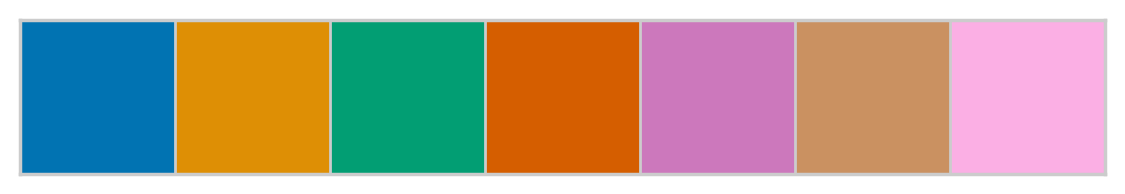

deep


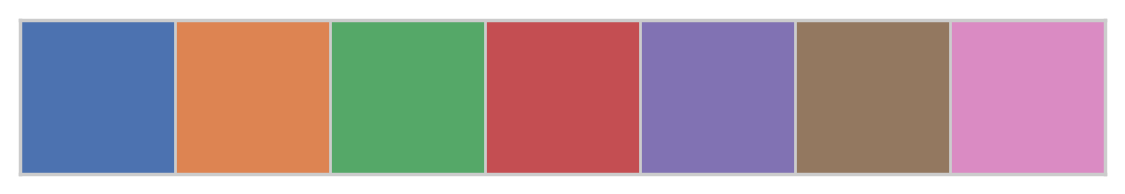

viridis


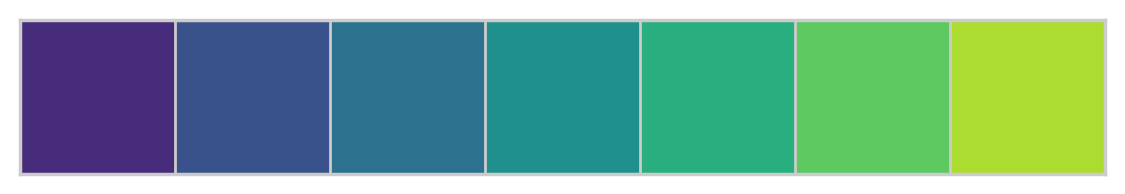

vlag


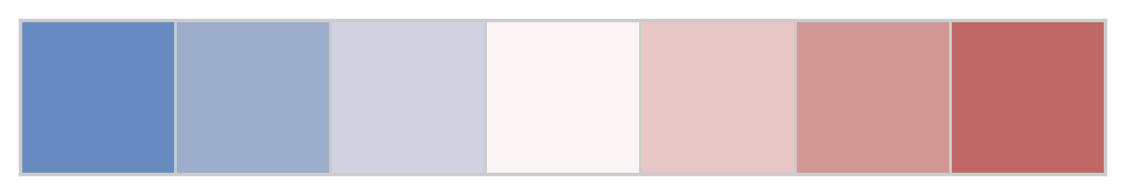

In [10]:
for name in ["colorblind", "deep", "viridis", "vlag"]:
    print(name)
    sns.palplot(sns.color_palette(name, 7))
    plt.show()

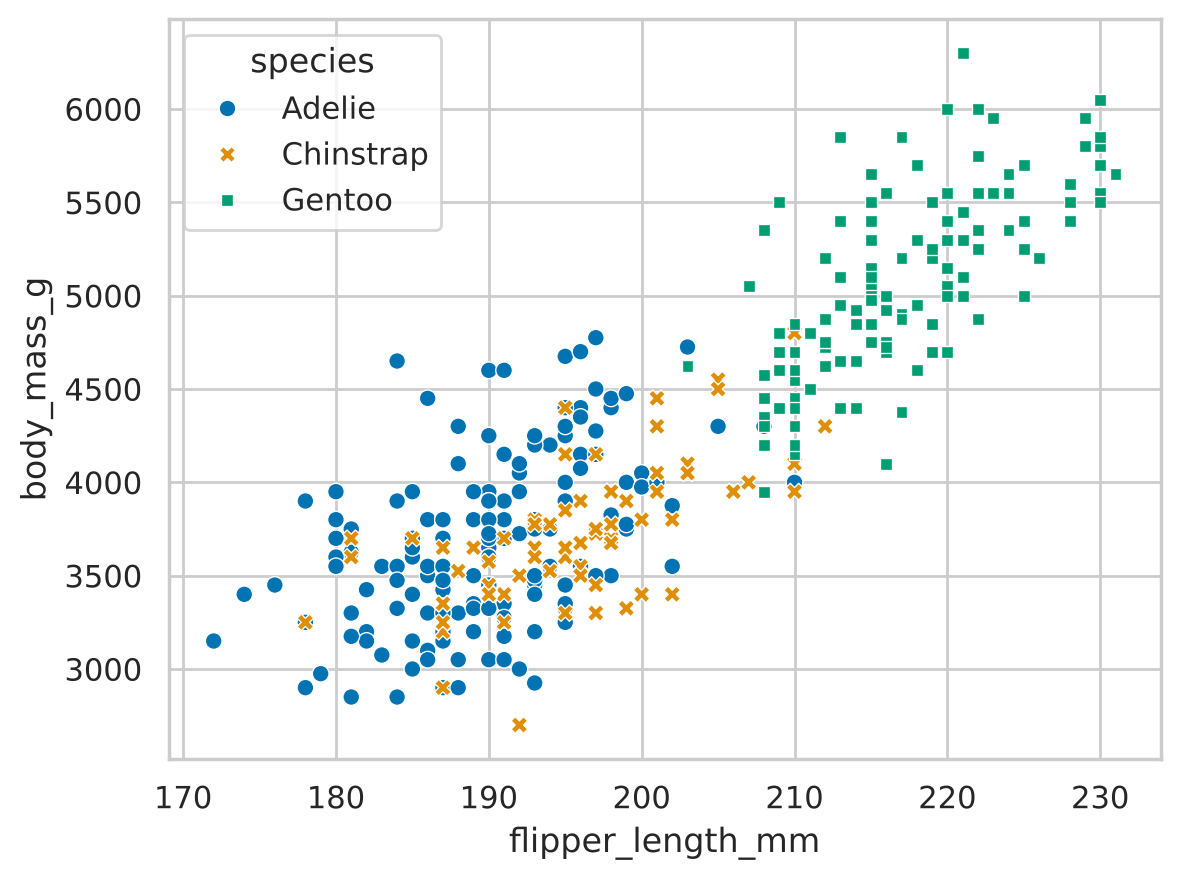

In [11]:
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species",
                style="species", palette="colorblind")
plt.show()

`style="species"` gives each species its own marker as well as its own colour, so the plot still works
without colour.

A palette can also be a dictionary, fixing each group's colour so it stays the same in every chart of a
report:

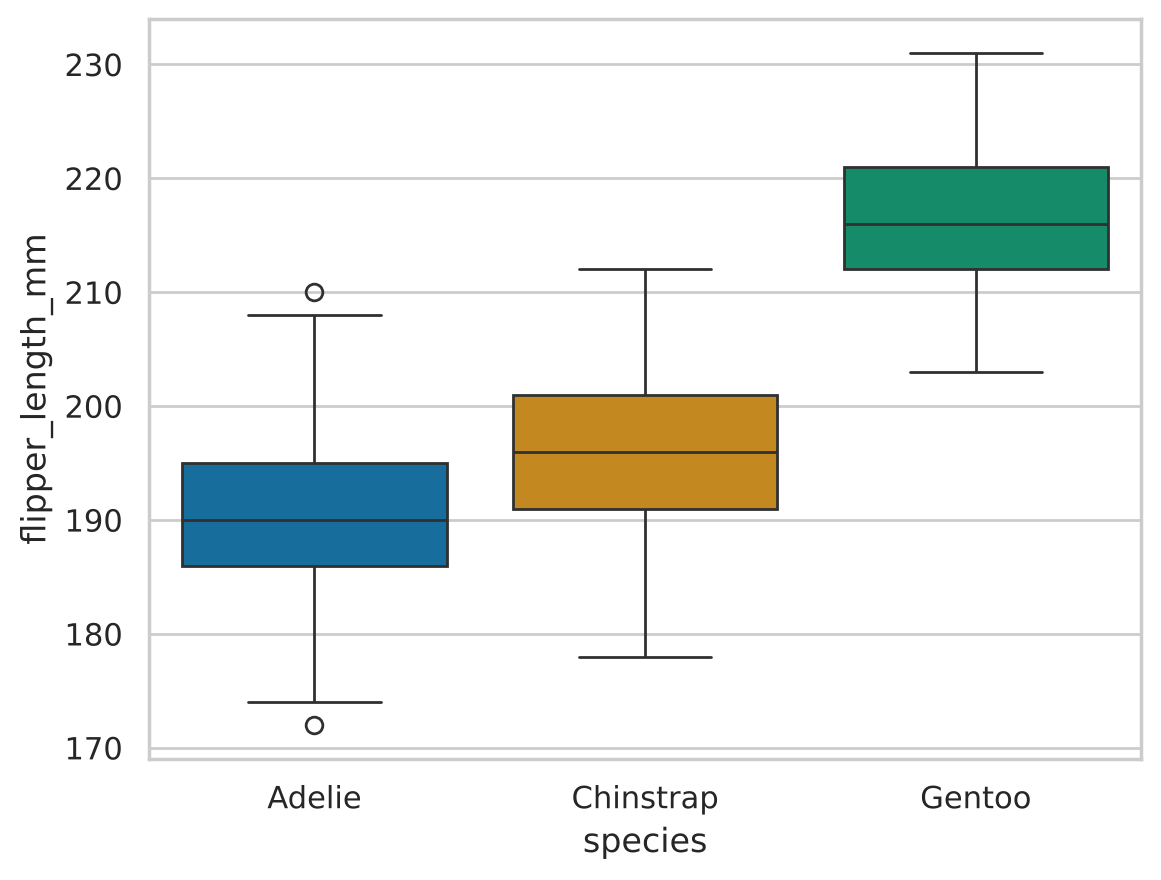

In [12]:
species_colours = dict(zip(["Adelie", "Chinstrap", "Gentoo"], sns.color_palette("colorblind", 3)))
sns.boxplot(data=penguins, x="species", y="flipper_length_mm", hue="species", palette=species_colours)
plt.show()

## Practise

Exercises for this folder are in `exercises/Seaborn_Exercises.ipynb`.

## Further reading

- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)
- [Overview of plotting functions](https://seaborn.pydata.org/tutorial/function_overview.html)
- [Controlling figure aesthetics](https://seaborn.pydata.org/tutorial/aesthetics.html)
- [Choosing colour palettes](https://seaborn.pydata.org/tutorial/color_palettes.html)